# 03 - Modeling: will this sensor fail within the next H hours?
**Project:** Predictive Maintenance of IoT Sensors (Intel Berkeley Research Lab)
**CRISP-DM phase:** 4 - Modeling

## 0. Setup

In [ ]:
import sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
try:                                    # Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/sensor-failure-prediction")
except ImportError:
    PROJECT = Path("..").resolve()

PROC_DIR  = PROJECT / "data/processed"
MODEL_DIR = PROJECT / "models";          MODEL_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR   = PROJECT / "reports/results"; RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR   = PROJECT / "reports/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

FAST = False          # True = quick dry run. Keep False for the real results.
SEED = 42
HORIZONS = [12, 24, 48, 72]       # hours
H_FINAL = 24                      # horizon kept for the final model: CHECK against the table in section 4, then edit
N_FOLDS, N_TEST_NODES = 5, 10
STRIDE = 3                        # train on every 3rd normal 10-min bin (neighbours are near-duplicates); all positives are kept
T_CUT = pd.Timestamp("2004-03-19")   # forward-in-time test: train before, test after
WINDOW_MAX_H = 48

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

Mounted at /content/drive


## 1. Load, and lock the test nodes
We split by **node**: a few nodes are kept locked for notebook 04 (1 silent node and 9 garbage nodes, chosen at random).
The other nodes (the *development* nodes) are used for everything in this notebook.

In [ ]:
data = pd.read_parquet(PROC_DIR / "features_intel.parquet")
FEATS = json.load(open(PROC_DIR / "feature_names_intel.json"))
onsets = pd.read_csv(PROC_DIR / "mote_onsets.csv", index_col="moteid", parse_dates=["first_ts", "last_ts", "t_onset", "t_lowv"])

nodes = sorted(data.moteid.unique())
rng = np.random.default_rng(SEED)
fail_nodes = [m for m in nodes if onsets.loc[m, "fail_type"] in ("garbage", "silent")]
g_nodes = [m for m in fail_nodes if onsets.loc[m, "fail_type"] == "garbage"]
s_nodes = [m for m in fail_nodes if onsets.loc[m, "fail_type"] == "silent"]
test_nodes = sorted(int(m) for m in list(rng.choice(g_nodes, min(N_TEST_NODES - 1, len(g_nodes)), replace=False))
                    + list(rng.choice(s_nodes, min(1, len(s_nodes)), replace=False)))
dev_nodes = [m for m in nodes if m not in test_nodes]

dev = data[data.moteid.isin(dev_nodes)].reset_index()      # columns: timestamp, features, moteid, ttf_h, fail_type
del data                                                    # the test rows are NOT kept in memory here
json.dump({"test_nodes": test_nodes, "dev_nodes": [int(m) for m in dev_nodes]}, open(PROC_DIR / "split_nodes.json", "w"))
print(f"development nodes: {len(dev_nodes)} | locked test nodes: {len(test_nodes)} | development rows: {len(dev):,}")

Xd, node, ttf, ts = dev[FEATS], dev.moteid.values, dev.ttf_h.values, dev.timestamp
def labels(H): return (ttf <= H).astype(int)                 # NaN (never fails) -> 0

pd.DataFrame({f"H={H} h": {"positive rows": int(labels(H).sum()), "positive rate %": labels(H).mean() * 100,
                           "nodes with positives": len(set(node[labels(H) == 1]))} for H in HORIZONS})

development nodes: 41 | locked test nodes: 10 | development rows: 83,205


,H=12 h,H=24 h,H=48 h,H=72 h
positive rows,"2,330.000","4,382.000","8,980.000","13,453.000"
positive rate %,2.800,5.267,10.793,16.168
nodes with positives,37.000,39.000,40.000,40.000


## 2. Evaluation helpers and simple baselines
Baselines need no training: the **risk score is a feature**.
- `-voltage` (6 h mean): the lower the voltage, the higher the risk.
- `volt_low_share_24h`: the share of the last 24 h below 2.4 V.

In [ ]:
def metrics(y, s):
    ok = ~np.isnan(s)
    y, s = y[ok], s[ok]
    pr = average_precision_score(y, s)
    return {"pr_auc": pr, "lift": pr / y.mean(), "roc_auc": roc_auc_score(y, s), "base_rate": float(y.mean())}

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i]), float(prec[i]), float(rec[i])

BASELINES = {"rule: low voltage (6 h mean)": -dev.volt_mean_6h.values,
             "rule: share of 24 h below 2.4 V": dev.volt_low_share_24h.values}

rows = []
for H in HORIZONS:
    for name, s in BASELINES.items():
        rows.append({"horizon_h": H, "model": name, **metrics(labels(H), s)})
base_tab = pd.DataFrame(rows)
base_tab.pivot(index="model", columns="horizon_h", values="lift")

horizon_h,12,24,48,72
model,,,,
rule: low voltage (6 h mean),12.775,12.136,7.753,5.582
rule: share of 24 h below 2.4 V,13.041,11.571,8.184,5.664


The table shows the **lift** of each rule. This is the level the models have to beat.

## 3. Models and leave-nodes-out cross-validation

In [ ]:
def make_model(name, y_tr, weighted=True):
    spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1) if weighted else 1.0
    cw = "balanced" if weighted else None
    if name == "LogisticRegression":
        return make_pipeline(StandardScaler(), LogisticRegression(class_weight=cw, C=0.1, max_iter=3000))
    if name == "DecisionTree":
        return DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, class_weight=cw, random_state=SEED)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=40 if FAST else 250, max_depth=12, min_samples_leaf=50,
                                      class_weight="balanced_subsample" if weighted else None, max_samples=0.5,
                                      n_jobs=-1, random_state=SEED)
    return XGBClassifier(n_estimators=60 if FAST else 300, max_depth=4, learning_rate=0.05, subsample=0.8,
                         colsample_bytree=0.7, min_child_weight=5, scale_pos_weight=spw,
                         eval_metric="aucpr", tree_method="hist", n_jobs=-1, random_state=SEED)

# Folds by node, balanced by failure time (the nodes are sorted by failure time and dealt like cards)
order = onsets.loc[dev_nodes].sort_values("t_onset", na_position="last").index
fold_of = {int(m): i % N_FOLDS for i, m in enumerate(order)}
fold = np.array([fold_of[int(m)] for m in node])
print("nodes per fold:", np.bincount([fold_of[int(m)] for m in dev_nodes]))

def run_cv(name, H, weighted=True):
    y = labels(H); s = np.full(len(dev), np.nan)
    for k in range(N_FOLDS):
        te = fold == k
        sub = (~te) & ((y == 1) | (np.arange(len(y)) % STRIDE == 0))
        m = make_model(name, y[sub], weighted).fit(Xd[sub], y[sub])
        s[te] = m.predict_proba(Xd[te])[:, 1]
    return s

MODELS = ["LogisticRegression", "DecisionTree", "RandomForest", "XGBoost"]
oof, rows, t_start = {}, [], time.time()
for H in HORIZONS:
    for name in MODELS:
        t0 = time.time()
        oof[(H, name)] = s = run_cv(name, H)
        y = labels(H)
        per_fold = [average_precision_score(y[fold == k], s[fold == k]) for k in range(N_FOLDS) if y[fold == k].sum() > 0]
        rows.append({"horizon_h": H, "model": name, **metrics(y, s), "pr_auc_fold_std": float(np.std(per_fold))})
        print(f"H={H:>2}h | {name:19s} | PR-AUC {rows[-1]['pr_auc']:.3f} | lift {rows[-1]['lift']:5.1f} | {time.time()-t0:3.0f}s")
cv_tab = pd.DataFrame(rows)
cv_tab.to_csv(RES_DIR / "intel_cv_results.csv", index=False)
print(f"total {(time.time()-t_start)/60:.1f} min")

nodes per fold: [9 8 8 8 8]
H=12h | LogisticRegression  | PR-AUC 0.968 | lift  34.6 |   2s
H=12h | DecisionTree        | PR-AUC 0.826 | lift  29.5 |   2s
H=12h | RandomForest        | PR-AUC 0.920 | lift  32.9 |  40s
H=12h | XGBoost             | PR-AUC 0.947 | lift  33.8 |  17s
H=24h | LogisticRegression  | PR-AUC 0.935 | lift  17.8 |   3s
H=24h | DecisionTree        | PR-AUC 0.743 | lift  14.1 |   4s
H=24h | RandomForest        | PR-AUC 0.868 | lift  16.5 |  47s
H=24h | XGBoost             | PR-AUC 0.902 | lift  17.1 |  11s
H=48h | LogisticRegression  | PR-AUC 0.884 | lift   8.2 |   4s
H=48h | DecisionTree        | PR-AUC 0.751 | lift   7.0 |   5s
H=48h | RandomForest        | PR-AUC 0.873 | lift   8.1 |  64s
H=48h | XGBoost             | PR-AUC 0.863 | lift   8.0 |  14s
H=72h | LogisticRegression  | PR-AUC 0.911 | lift   5.6 |   3s
H=72h | DecisionTree        | PR-AUC 0.850 | lift   5.3 |   6s
H=72h | RandomForest        | PR-AUC 0.926 | lift   5.7 |  75s
H=72h | XGBoost            

horizon_h,12,24,48,72
model,,,,
LogisticRegression,34.551,17.755,8.190,5.632
XGBoost,33.830,17.124,7.997,5.651
RandomForest,32.864,16.478,8.086,5.725
DecisionTree,29.514,14.104,6.960,5.260
rule: low voltage (6 h mean),12.775,12.136,7.753,5.582
rule: share of 24 h below 2.4 V,13.041,11.571,8.184,5.664


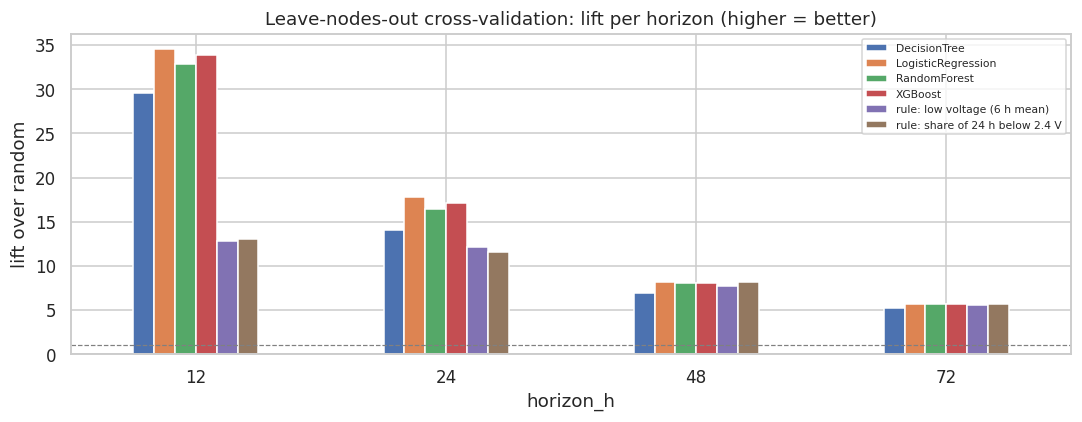

In [ ]:
res = pd.concat([cv_tab[["horizon_h", "model", "pr_auc", "lift", "roc_auc", "base_rate"]], base_tab])
piv = res.pivot(index="model", columns="horizon_h", values="lift")
display(piv.sort_values(H_FINAL, ascending=False))

fig, ax = plt.subplots(figsize=(10, 4))
piv.T.plot.bar(ax=ax, rot=0); ax.axhline(1, color="gray", ls="--", lw=0.8)
ax.set_ylabel("lift over random"); ax.set_title("Leave-nodes-out cross-validation: lift per horizon (higher = better)")
ax.legend(fontsize=7, loc="upper right"); plt.tight_layout(); plt.savefig(FIG_DIR / "08_intel_lift.png", bbox_inches="tight"); plt.show()

## 4. Imbalance check (at `H_FINAL`)
Positives are 1 to 16 % of the rows, so the imbalance is moderate. We check that class weights help (XGBoost, same folds). No SMOTE.

In [ ]:
y = labels(H_FINAL)
a = metrics(y, run_cv("XGBoost", H_FINAL, weighted=False))
b = metrics(y, oof[(H_FINAL, "XGBoost")])
pd.DataFrame({"no weighting": a, "class weights": b}).T

,pr_auc,lift,roc_auc,base_rate
no weighting,0.904,17.171,0.991,0.053
class weights,0.902,17.124,0.990,0.053


## 5. Harder check: forward in time
The failures cluster in time. Here we train **only on the early period** (before `T_CUT`, minus an embargo of H + 48 h so no label or feature window crosses the border)
and test on everything after. This asks: *does a model learned on the first few failures work on the later cluster?*

In [ ]:
y = labels(H_FINAL)
emb = pd.Timedelta(hours=H_FINAL + WINDOW_MAX_H)
tr = (ts < T_CUT - emb).values
te = (ts >= T_CUT).values
print(f"train rows {tr.sum():,} (positives {y[tr].sum()}, nodes with positives {len(set(node[tr & (y == 1)]))})"
      f" | test rows {te.sum():,} (positives {y[te].sum()}, nodes with positives {len(set(node[te & (y == 1)]))})")

fw = {}
for name, s in BASELINES.items():
    fw[name] = metrics(y[te], s[te])
if y[tr].sum() >= 30:
    sub = tr & ((y == 1) | (np.arange(len(y)) % STRIDE == 0))
    for name in MODELS:
        m = make_model(name, y[sub]).fit(Xd[sub], y[sub])
        fw[name] = metrics(y[te], m.predict_proba(Xd[te])[:, 1])
else:
    print("Too few early positives to train. Move T_CUT later.")
fw_tab = pd.DataFrame(fw).T.sort_values("lift", ascending=False)
fw_tab

train rows 63,178 (positives 156, nodes with positives 3) | test rows 17,424 (positives 4061, nodes with positives 35)


,pr_auc,lift,roc_auc,base_rate
LogisticRegression,0.711,3.050,0.894,0.233
XGBoost,0.673,2.886,0.886,0.233
RandomForest,0.669,2.872,0.901,0.233
rule: low voltage (6 h mean),0.647,2.775,0.880,0.233
rule: share of 24 h below 2.4 V,0.610,2.617,0.887,0.233
DecisionTree,0.347,1.488,0.713,0.233


## 6. Choose the model and the alert threshold

In [ ]:
cand = cv_tab[cv_tab.horizon_h == H_FINAL].sort_values("pr_auc", ascending=False)
best_name = cand.iloc[0].model
print("Best model at H =", H_FINAL, "h (cross-validation PR-AUC):", best_name, "| lift", round(cand.iloc[0].lift, 1))
print("Best rule at the same horizon: lift", round(base_tab[base_tab.horizon_h == H_FINAL].lift.max(), 1))

y = labels(H_FINAL); s_best = oof[(H_FINAL, best_name)]
thr, f1, prec, rec = best_f1_threshold(y, s_best)
print(f"\nThreshold (max F1, out-of-fold): {thr:.3f} -> precision {prec:.3f}, recall {rec:.3f}")

p, r, t = precision_recall_curve(y, s_best)
ops = []
for target in [0.6, 0.7, 0.8, 0.9]:
    ok = np.where(r[:-1] >= target)[0]
    if len(ok):
        i = ok[np.argmax(p[:-1][ok])]
        ops.append({"recall target": target, "threshold": t[i], "precision": p[i], "recall": r[i]})
pd.DataFrame(ops)

Best model at H = 24 h (cross-validation PR-AUC): LogisticRegression | lift 17.8
Best rule at the same horizon: lift 12.1

Threshold (max F1, out-of-fold): 0.937 -> precision 0.888, recall 0.816


,recall target,threshold,precision,recall
0,0.600,0.997,0.994,0.613
1,0.700,0.986,0.972,0.701
2,0.800,0.948,0.902,0.800
3,0.900,0.818,0.760,0.900


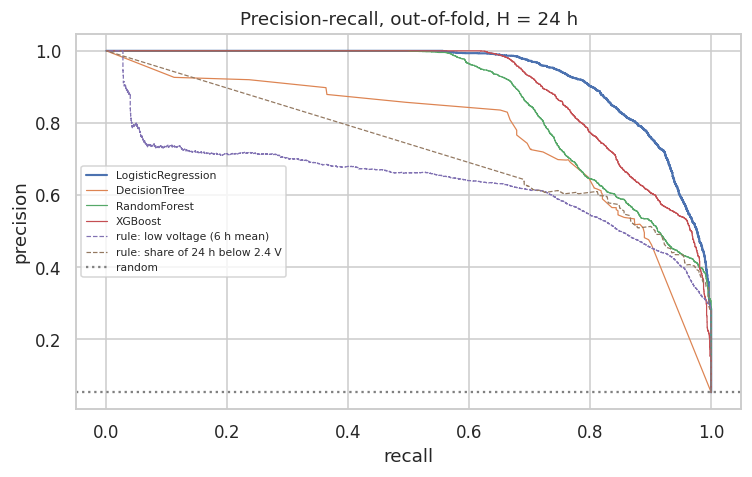

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name in MODELS:
    p, r, _ = precision_recall_curve(y, oof[(H_FINAL, name)])
    ax.plot(r, p, label=name, lw=1.4 if name == best_name else 0.8)
for name, s in BASELINES.items():
    p, r, _ = precision_recall_curve(y, s); ax.plot(r, p, ls="--", lw=0.8, label=name)
ax.axhline(y.mean(), color="gray", ls=":", label="random"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title(f"Precision-recall, out-of-fold, H = {H_FINAL} h"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "09_intel_pr_curves.png", bbox_inches="tight"); plt.show()

## 7. Save for notebook 04

In [ ]:
# Final model: trained on ALL development nodes, never on the test nodes
sub = (y == 1) | (np.arange(len(y)) % STRIDE == 0)
final = make_model(best_name, y[sub]).fit(Xd[sub], y[sub])
joblib.dump({"name": best_name, "model": final, "features": FEATS, "horizon_h": H_FINAL, "threshold_oof": thr,
             "note": "trained on development nodes only; threshold from out-of-fold predictions; test nodes locked"},
            MODEL_DIR / "best_model_intel.joblib")

oofdf = dev[["timestamp", "moteid", "ttf_h"]].copy()
oofdf["y"] = y
for name in MODELS: oofdf[name] = oof[(H_FINAL, name)]
for name, s_ in BASELINES.items(): oofdf[name] = s_
oofdf.to_parquet(RES_DIR / "intel_oof_predictions.parquet")

json.dump({"best_model": best_name, "H_final": H_FINAL, "threshold_oof": thr, "cv_pr_auc": float(cand.iloc[0].pr_auc),
           "cv_lift": float(cand.iloc[0].lift), "test_nodes": test_nodes}, open(RES_DIR / "intel_best_model_summary.json", "w"), indent=2)
print("Saved:", [p.name for p in MODEL_DIR.glob("*")])

Saved: ['best_model_intel.joblib']


In [ ]:
TH = [c for c in FEATS if c.startswith("temp_") or c.startswith("hum_")]
GROUPS = {"all 48 features": FEATS,
          "voltage + reporting + network (no temperature / humidity)": [c for c in FEATS if c not in TH],
          "temperature + humidity only": TH}

def run_cv_cols(name, H, cols):
    y = labels(H); s = np.full(len(dev), np.nan)
    for k in range(N_FOLDS):
        te = fold == k
        sub = (~te) & ((y == 1) | (np.arange(len(y)) % STRIDE == 0))
        m = make_model(name, y[sub]).fit(Xd.loc[sub, cols], y[sub])
        s[te] = m.predict_proba(Xd.loc[te, cols])[:, 1]
    return s

rows = []
for H in HORIZONS:
    for gname, cols in GROUPS.items():
        s = run_cv_cols("LogisticRegression", H, cols)
        rows.append({"horizon_h": H, "features": gname, **metrics(labels(H), s)})
abl = pd.DataFrame(rows)
abl.to_csv(RES_DIR / "intel_ablation.csv", index=False)
display(abl.pivot(index="features", columns="horizon_h", values="lift"))
display(abl.pivot(index="features", columns="horizon_h", values="pr_auc"))

horizon_h,12,24,48,72
features,,,,
all 48 features,34.551,17.755,8.190,5.632
temperature + humidity only,33.123,16.384,7.055,4.568
voltage + reporting + network (no temperature / humidity),17.125,11.864,7.735,5.586


horizon_h,12,24,48,72
features,,,,
all 48 features,0.968,0.935,0.884,0.911
temperature + humidity only,0.928,0.863,0.761,0.739
voltage + reporting + network (no temperature / humidity),0.480,0.625,0.835,0.903
